<a href="https://colab.research.google.com/github/AdithyaRai/Cats-VS-Dogs-CNN/blob/main/Cats_vs_Dogs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Found 1598 files belonging to 2 classes.
Found 402 files belonging to 2 classes.
Class Names: ['cats', 'dogs']


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     5,308,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,550,273 (21.17 MB)

 Trainable params: 5,550,273 (21.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 226s 4s/step - accuracy: 0.5131 - loss: 0.7129 - val_accuracy: 0.5348 - val_loss: 0.6927
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.5200 - loss: 0.6883 - val_accuracy: 0.5199 - val_loss: 0.6906
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 180ms/step - accuracy: 0.5438 - loss: 0.6773 - val_accuracy: 0.5373 - val_loss: 0.6826
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 175ms/step - accuracy: 0.5870 - loss: 0.6642 - val_accuracy: 0.5721 - val_loss: 0.6571
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 179ms/step - accuracy: 0.6089 - loss: 0.6582 - val_accuracy: 0.6393 - val_loss: 0.6417
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 181ms/step - accuracy: 0.6214 - loss: 0.6427 - val_accuracy: 0.6343 - val_loss: 0.6191
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 179ms/step - accuracy: 0.6558 - loss: 0.6042 - val_accuracy: 0.6169 - val_loss: 0.6173
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 182ms/step - accuracy: 0.6840 - loss: 0.5977 - val_accuracy: 0

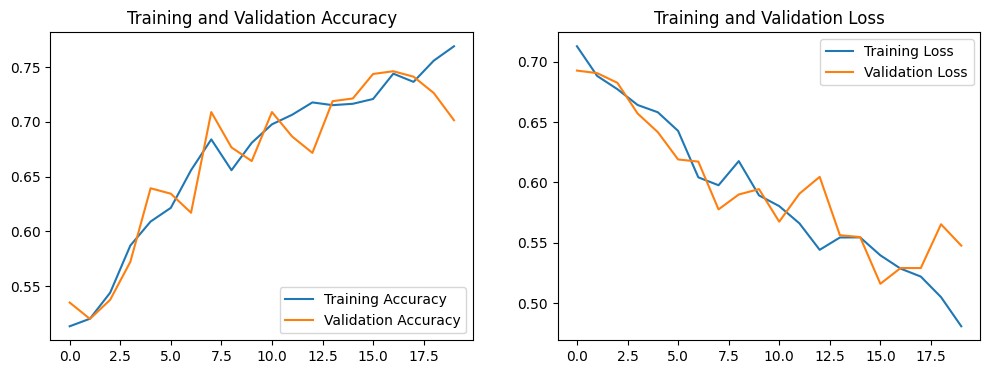

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory

# 1. Hyperparameters & Configuration
BATCH_SIZE = 32
IMG_SIZE = (150, 150)
EPOCHS = 20
AUTOTUNE = tf.data.AUTOTUNE

# Update this path to where your dataset is extracted
# Expected structure: dataset_dir/train/cats, dataset_dir/train/dogs, etc.
DATASET_DIR = "/content/drive/MyDrive/cats-vs-dogs-dataset"  # Change to your local path

# 2. Dataset Loading with Data Augmentation
# It is recommended to split your dataset into train and validation directories beforehand.
train_dir = os.path.join(DATASET_DIR, "train")
val_dir = os.path.join(DATASET_DIR, "test")  # or validation directory

# Training dataset with data augmentation to prevent overfitting
train_dataset = image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",  # Binary classification: 0 for Cat, 1 for Dog
)

val_dataset = image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary"
)

class_names = train_dataset.class_names
print(f"Class Names: {class_names}")

# Data Augmentation pipeline
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ]
)

# Apply prefetching and caching for optimal performance during training
train_dataset = (
    train_dataset.map(
        lambda x, y: (data_augmentation(x, training=True), y),
        num_parallel_calls=AUTOTUNE,
    )
    .prefetch(buffer_size=AUTOTUNE)
)

val_dataset = val_dataset.prefetch(buffer_size=AUTOTUNE)


# 3. Building the CNN Architecture
def create_model():
    model = models.Sequential(
        [
            # Rescaling layer to normalize pixel values from [0, 255] to [0, 1]
            layers.Rescaling(1.0 / 255, input_shape=(150, 150, 3)),
            # Block 1
            layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
            # Block 2
            layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
            # Block 3
            layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
            # Block 4
            layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
            layers.MaxPooling2D((2, 2)),
            # Classifier Head
            layers.Flatten(),
            layers.Dropout(0.5),  # Dropout for regularization
            layers.Dense(512, activation="relu"),
            layers.Dense(
                1, activation="sigmoid"
            ),  # Sigmoid for binary output (0 or 1)
        ]
    )

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


model = create_model()
model.summary()

# 4. Callbacks (Early Stopping & Model Checkpointing)
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_cat_dog_model.keras", save_best_only=True
    ),
]

# 5. Model Training
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
)


# 6. Plotting Training History
def plot_history(history):
    acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label="Training Accuracy")
    plt.plot(epochs_range, val_acc, label="Validation Accuracy")
    plt.legend(loc="lower right")
    plt.title("Training and Validation Accuracy")

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label="Training Loss")
    plt.plot(epochs_range, val_loss, label="Validation Loss")
    plt.legend(loc="upper right")
    plt.title("Training and Validation Loss")
    plt.show()


plot_history(history)


# 7. Prediction Function for New Images
def predict_image(image_path):
    img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)  # Create a batch

    predictions = model.predict(img_array)
    score = predictions[0][0]

    # Threshold at 0.5 (Binary output)
    if score > 0.5:
        print(
            f"This image is predicted to be a **Dog** with a confidence of {score * 100:.2f}%."
        )
    else:
        print(
            f"This image is predicted to be a **Cat** with a confidence of {(1 - score) * 100:.2f}%."
        )

### Transfer Learning with MobileNetV2

Using a model pre-trained on ImageNet allows us to leverage complex feature extractors already optimized on millions of images. We will freeze the MobileNetV2 base and only train our custom classifier head on top.

/tmp/ipykernel_6473/2065273261.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/lambda_layer.py:65: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 31s 407ms/step - accuracy: 0.8223 - loss: 0.3653 - val_accuracy: 0.9502 - val_loss: 0.1382
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 186ms/step - accuracy: 0.9243 - loss: 0.1759 - val_accuracy: 0.9577 - val_loss: 0.1032
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 186ms/step - accuracy: 0.9424 - loss: 0.1536 - val_accuracy: 0.9577 - val_loss: 0.0929
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 187ms/step - accuracy: 0.9537 - loss: 0.1283 - val_accuracy: 0.9627 - val_loss: 0.0883
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 171ms/step - accuracy: 0.9524 - loss: 0.1279 - val_accuracy: 0.9627 - val_loss: 0.0908
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 181ms/step - accuracy: 0.9437 - loss: 0.1322 - val_accuracy: 0.9677 - val_loss: 0.0844
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 169ms/step - accuracy: 0.9574 - loss: 0.1143 - val_accuracy: 0.9627 - val_loss: 0.0911
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 182ms/step - accuracy: 0.9512 - loss: 0.1209 - val_accuracy

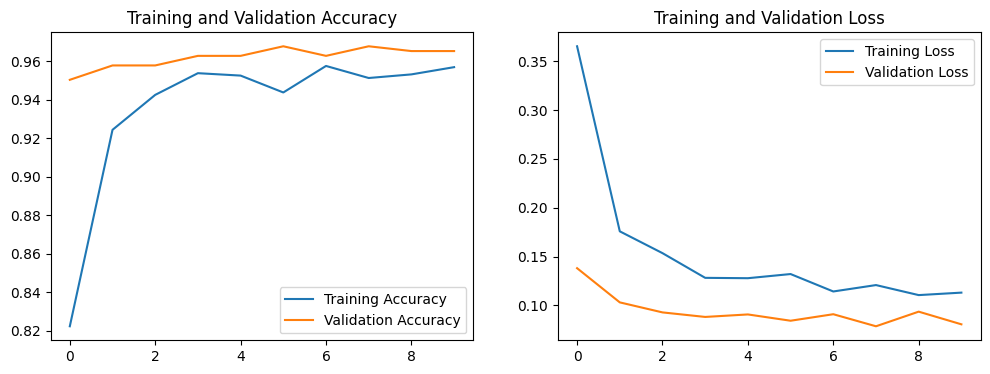

In [2]:
# 1. Load MobileNetV2 pre-trained on ImageNet without its classification head
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the base model to prevent its weights from being updated
base_model.trainable = False

# 2. Build the Transfer Learning Model
def create_transfer_model():
    model = models.Sequential([
        # Preprocess input matching MobileNetV2 requirements (scales pixels to [-1, 1])
        layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input, input_shape=(150, 150, 3)),

        base_model,

        # Global average pooling to reduce spatial dimensions
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

transfer_model = create_transfer_model()
transfer_model.summary()

# 3. Define specific callbacks for Transfer Learning
transfer_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint('best_mobilenet_cat_dog.keras', save_best_only=True)
]

# 4. Train the Model
transfer_history = transfer_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10, # Transfer learning usually converges much faster
    callbacks=transfer_callbacks
)

# 5. Plot Results
plot_history(transfer_history)